# Justificación de ventana temporal para analitos de cristal

Este notebook compara ventanas de 1 a 12 horas para predecir **cada analito** de cristal sin refinar y refinado usando `tabla_limpia_valores.xlsx`.

- La evaluación es temporal: se reserva el último **20% del calendario** como prueba, sin barajar registros.
- Cada objetivo en la hora `t` usa únicamente variables independientes de `t-1` a `t-W`.
- Se mantienen los faltantes; no se imputan ni interpolan. Los modelos de árboles usados aquí aceptan `NaN`.
- No se presupone que cinco horas sea la mejor ventana. La selección se informa por analito a partir del RMSE del período reservado.

Ejecuta el notebook desde la carpeta donde están este archivo y `tabla_limpia_valores.xlsx`.

### 1. Librerías, objetivos y variables independientes

In [15]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 1
DATA_FILE = Path("tabla_limpia_valores.xlsx")
DATETIME_COL = "Fecha_hora"
FRACTION_TEST = 0.20
WINDOW_HOURS = 5  # editable; la ventana se compara empíricamente en el otro notebook

TARGETS_SIN_REFINAR = [
    "Cristal sin refinar Cl",
    "Cristal sin refinar SO4",
    "Cristal sin refinar Ca",
    "Cristal sin refinar Mg",
    "Cristal sin refinal ClO4",
]
TARGETS_REFINADO = [
    "Cristal Refinado Cl",
    "Cristal Refinado SO4",
    "Cristal Refinado Ca",
    "Cristal Refinado Mg",
    "Cristal refinado ClO4",
]
ALL_TARGETS = TARGETS_SIN_REFINAR + TARGETS_REFINADO

# Lista independiente indicada para Cristal Sin Refinar.
FEATURES_SIN_REFINAR = [
    "Temp_Cristalización2_A3000",
    "T Cry A3110",
    "Agua de lavado Cf3000",
    "SSK NANO3",
    "SSK CL",
    "SSK SO4",
    "SSK K",
    "SSK MG",
    "SSK CA",
    "SSK KCLO4 IC",
    "SSKCLO4 IC",
    "Flujo SSK",
    "Flujo SSKd",
    "Agua de dilución",
    "Purga_Recirculacion NaNO3",
    "Purga_Recirculación SO4",
    "Purga_Recirculacion K",
    "Purga_Recirculación Ca",
    "Purga_Recirculación Mg",
    "Purga_Recirculación KClO4 IC",
    "Purga_Recirculación ClO4 IC",
]

### 2. Lectura de `tabla_limpia_valores.xlsx` y revisión de datos

In [16]:
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"No encuentro {DATA_FILE}. Ejecuta el notebook desde la carpeta SQM "
        "donde están los notebooks y tabla_limpia_valores.xlsx. "
        f"Carpeta actual: {Path.cwd()}"
    )

raw = pd.read_excel(DATA_FILE, sheet_name=0)
if DATETIME_COL not in raw.columns:
    raise KeyError(f"Falta la columna temporal {DATETIME_COL!r} en {DATA_FILE}")

raw[DATETIME_COL] = pd.to_datetime(raw[DATETIME_COL], errors="coerce")
invalid_time_rows = int(raw[DATETIME_COL].isna().sum())
raw = raw.dropna(subset=[DATETIME_COL]).sort_values(DATETIME_COL).copy()
if raw[DATETIME_COL].duplicated().any():
    duplicated = raw.loc[raw[DATETIME_COL].duplicated(keep=False), DATETIME_COL]
    raise ValueError(f"Hay timestamps duplicados en destino: {duplicated.head().tolist()}")

numeric_cols = [c for c in raw.columns if c != DATETIME_COL]
raw_numeric = raw[numeric_cols].copy()
numeric = raw_numeric.apply(pd.to_numeric, errors="coerce")
coercion_mask = raw_numeric.notna() & numeric.isna()
coercion_report = coercion_mask.sum().loc[lambda s: s > 0].rename("textos_no_numericos_convertidos_a_faltante")

# No se imputan ni interpolan celdas vacías. HistGradientBoostingRegressor maneja NaN.
df = numeric.copy()
df.index = pd.DatetimeIndex(raw[DATETIME_COL], name=DATETIME_COL)
df = df.sort_index()

missing_columns = [c for c in FEATURES_SIN_REFINAR + ALL_TARGETS if c not in df.columns]
if missing_columns:
    raise KeyError(f"Faltan columnas requeridas en el XLSX: {missing_columns}")

# Para Cristal Refinado se usan todas las columnas cuantitativas disponibles,
# excluyendo los analitos de ambos productos para evitar fuga del objetivo.
FEATURES_REFINADO = [c for c in df.columns if c not in ALL_TARGETS]

cutoff_position = int(np.floor((1 - FRACTION_TEST) * len(df.index)))
cutoff_time = df.index[cutoff_position]
print(f"Archivo: {DATA_FILE.resolve()}")
print(f"Filas temporales: {len(df):,}; período: {df.index.min()} a {df.index.max()}")
print(f"Corte temporal: {cutoff_time}; prueba = último {FRACTION_TEST:.0%} del calendario")
print(f"Filas con fecha inválida excluidas: {invalid_time_rows}")
print(f"Variables independientes Sin Refinar: {len(FEATURES_SIN_REFINAR)}")
print(f"Variables independientes Refinado: {len(FEATURES_REFINADO)}")
if len(coercion_report):
    display(coercion_report.to_frame())
else:
    print("Textos no numéricos en columnas de datos: ninguno")

Archivo: /mnt/c/Users/SrLeo/Desktop/SQM/Predicción efecto de analitos/tabla_limpia_valores.xlsx
Filas temporales: 8,379; período: 2025-01-01 01:00:00 a 2025-12-16 04:00:00
Corte temporal: 2025-10-07 08:00:00; prueba = último 20% del calendario
Filas con fecha inválida excluidas: 0
Variables independientes Sin Refinar: 21
Variables independientes Refinado: 32


,textos_no_numericos_convertidos_a_faltante
Temp_Cristalización2_A3000,16
T Cry A3110,39
Temperatura ml refinación,34
Temperatura TK 6110,95
Temperatura TK6160,95
Agua de lavado Cf3000,16
Agua de lavado Cf 6000,97
Flujo SSK,40
Flujo SSKd,40
Agua de dilución,40


### 3. Corte final del 20% y construcción de retardos

In [17]:
def crear_split_temporal(data, features, target, window_size, cutoff):
    """Predice y(t) con variables independientes de t-1 a t-window_size."""
    X = pd.DataFrame(index=data.index)
    for lag in range(1, window_size + 1):
        for col in features:
            X[f"{col}__lag_{lag}h"] = data[col].shift(lag)
    y = data[target]

    # Conserva faltantes parciales; elimina solo objetivos ausentes o filas sin ningún predictor.
    keep = y.notna() & X.notna().any(axis=1)
    X, y = X.loc[keep], y.loc[keep]
    train_mask = X.index < cutoff
    test_mask = X.index >= cutoff
    X_train, X_test = X.loc[train_mask].copy(), X.loc[test_mask].copy()
    y_train, y_test = y.loc[train_mask].copy(), y.loc[test_mask].copy()

    # Una columna completamente vacía en entrenamiento no aporta y puede impedir el ajuste.
    usable = X_train.columns[X_train.notna().any(axis=0)]
    X_train, X_test = X_train.loc[:, usable], X_test.loc[:, usable]
    return X_train, X_test, y_train, y_test


def metricas(y_true, y_pred):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    std = float(np.std(y_true, ddof=0))
    return {
        "R2": float(r2_score(y_true, y_pred)) if len(y_true) > 1 else np.nan,
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": rmse,
        "NRMSE": rmse / std if std > 0 else np.nan,
    }

### 4. Barrido de ventanas de 1 a 12 horas

In [18]:
MAX_WINDOW = 12
MIN_TRAIN_ROWS = 50
result_rows = []

product_batches = [
    ("Sin Refinar", TARGETS_SIN_REFINAR, FEATURES_SIN_REFINAR),
    ("Refinado", TARGETS_REFINADO, FEATURES_REFINADO),
]
total_iteraciones = sum(
    len(targets) * (MAX_WINDOW - 2)
    for _, targets, _ in product_batches
)
iteracion = 0
inicio_barrido = time.perf_counter()

print(
    f"Inicio del barrido: {total_iteraciones} iteraciones "
    f"({MAX_WINDOW - 2} ventanas por analito)."
)

for product, targets, features in product_batches:
    for target in targets:
        for window in range(3, MAX_WINDOW + 1):
            iteracion += 1
            print(
                f"[{iteracion}/{total_iteraciones}] "
                f"{product} | {target} | ventana {window} h",
                flush=True,
            )

            inicio_iteracion = time.perf_counter()
            X_train, X_test, y_train, y_test = crear_split_temporal(
                df, features, target, window, cutoff_time
            )
            if len(X_train) < MIN_TRAIN_ROWS or len(X_test) < 2 or X_train.shape[1] == 0:
                continue

            model = HistGradientBoostingRegressor(
                max_iter=200, l2_regularization=1.0, random_state=SEED
            )
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            result_rows.append({
                "Producto": product,
                "Analito": target,
                "Ventana_h": window,
                "n_entrenamiento": len(y_train),
                "n_prueba": len(y_test),
                **metricas(y_test, y_pred),
            })

            duracion_iteracion = time.perf_counter() - inicio_iteracion
            tiempo_transcurrido = time.perf_counter() - inicio_barrido
            promedio_por_iteracion = tiempo_transcurrido / iteracion
            iteraciones_restantes = total_iteraciones - iteracion
            eta_segundos = promedio_por_iteracion * iteraciones_restantes
            porcentaje = 100 * iteracion / total_iteraciones

            print(
                f"  Completada en {duracion_iteracion:.1f} s | "
                f"progreso {porcentaje:.1f}% | "
                f"transcurrido {tiempo_transcurrido:.1f} s | "
                f"ETA {eta_segundos:.1f} s",
                flush=True,
            )

print(
    f"Barrido finalizado en "
    f"{time.perf_counter() - inicio_barrido:.1f} s.",
    flush=True,
)

resultados = pd.DataFrame(result_rows)
if resultados.empty:
    raise ValueError("No hay suficientes muestras observadas para comparar ventanas.")
resultados = resultados.sort_values(["Producto", "Analito", "Ventana_h"])
display(resultados)

Inicio del barrido: 100 iteraciones (10 ventanas por analito).
[1/100] Sin Refinar | Cristal sin refinar Cl | ventana 3 h
  Completada en 61.5 s | progreso 1.0% | transcurrido 61.5 s | ETA 6091.1 s
[2/100] Sin Refinar | Cristal sin refinar Cl | ventana 4 h
  Completada en 10.6 s | progreso 2.0% | transcurrido 72.2 s | ETA 3536.0 s
[3/100] Sin Refinar | Cristal sin refinar Cl | ventana 5 h


/tmp/ipykernel_1114/828488867.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[f"{col}__lag_{lag}h"] = data[col].shift(lag)


  Completada en 1.1 s | progreso 3.0% | transcurrido 73.3 s | ETA 2369.0 s
[4/100] Sin Refinar | Cristal sin refinar Cl | ventana 6 h


/tmp/ipykernel_1114/828488867.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[f"{col}__lag_{lag}h"] = data[col].shift(lag)


  Completada en 596.0 s | progreso 4.0% | transcurrido 669.3 s | ETA 16063.6 s
[5/100] Sin Refinar | Cristal sin refinar Cl | ventana 7 h


/tmp/ipykernel_1114/828488867.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[f"{col}__lag_{lag}h"] = data[col].shift(lag)


... (162 outputs left out)

  Completada en 3.1 s | progreso 99.0% | transcurrido 8087.3 s | ETA 81.7 s
[100/100] Refinado | Cristal refinado ClO4 | ventana 12 h


/tmp/ipykernel_1114/828488867.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[f"{col}__lag_{lag}h"] = data[col].shift(lag)


  Completada en 3.4 s | progreso 100.0% | transcurrido 8090.8 s | ETA 0.0 s
Barrido finalizado en 8090.8 s.


,Producto,Analito,Ventana_h,n_entrenamiento,n_prueba,R2,MAE,RMSE,NRMSE
70,Refinado,Cristal Refinado Ca,3,3412,849,-0.011521,0.005828,0.007761,1.005744
71,Refinado,Cristal Refinado Ca,4,3412,849,-0.084502,0.005836,0.008036,1.041394
72,Refinado,Cristal Refinado Ca,5,3412,849,0.000666,0.005785,0.007714,0.999667
73,Refinado,Cristal Refinado Ca,6,3412,849,0.033298,0.005805,0.007587,0.983210
74,Refinado,Cristal Refinado Ca,7,3412,849,0.028708,0.005661,0.007605,0.985541
...,...,...,...,...,...,...,...,...,...
15,Sin Refinar,Cristal sin refinar SO4,8,3083,801,-0.131196,0.087611,0.117475,1.063577
16,Sin Refinar,Cristal sin refinar SO4,9,3083,801,-0.185805,0.090754,0.120277,1.088947
17,Sin Refinar,Cristal sin refinar SO4,10,3083,801,-0.100260,0.087205,0.115858,1.048933
18,Sin Refinar,Cristal sin refinar SO4,11,3083,801,-0.104899,0.087202,0.116102,1.051142


### 5. Mejor ventana observada por analito

In [22]:
mejores_ventanas = (
    resultados.sort_values(["Producto", "Analito", "RMSE", "Ventana_h"])
    .groupby(["Producto", "Analito"], as_index=False)
    .first()
    [["Producto", "Analito", "Ventana_h", "n_entrenamiento", "n_prueba", "R2", "MAE", "RMSE", "NRMSE"]]
)
display(mejores_ventanas)

,Producto,Analito,Ventana_h,n_entrenamiento,n_prueba,R2,MAE,RMSE,NRMSE
0,Refinado,Cristal Refinado Ca,12,3412,849,0.063716,0.005735,0.007467,0.967618
1,Refinado,Cristal Refinado Cl,3,3291,800,-144.081296,0.084217,0.142874,12.044970
2,Refinado,Cristal Refinado Mg,9,3415,849,0.049046,0.002039,0.002870,0.975169
3,Refinado,Cristal Refinado SO4,11,3231,848,0.026108,0.048013,0.068902,0.986859
4,Refinado,Cristal refinado ClO4,4,3235,848,-0.131391,12.709095,20.272393,1.063669
5,Sin Refinar,Cristal sin refinal ClO4,3,3077,750,0.043091,251.883609,373.889481,0.978217
6,Sin Refinar,Cristal sin refinar Ca,6,2733,801,0.172037,0.008617,0.010570,0.909925
7,Sin Refinar,Cristal sin refinar Cl,3,3080,801,-2.304459,0.361349,0.681722,1.817817
8,Sin Refinar,Cristal sin refinar Mg,8,3081,799,0.626029,0.021713,0.027751,0.611531
9,Sin Refinar,Cristal sin refinar SO4,10,3083,801,-0.100260,0.087205,0.115858,1.048933


### 6. Curvas de error en el período temporal reservado

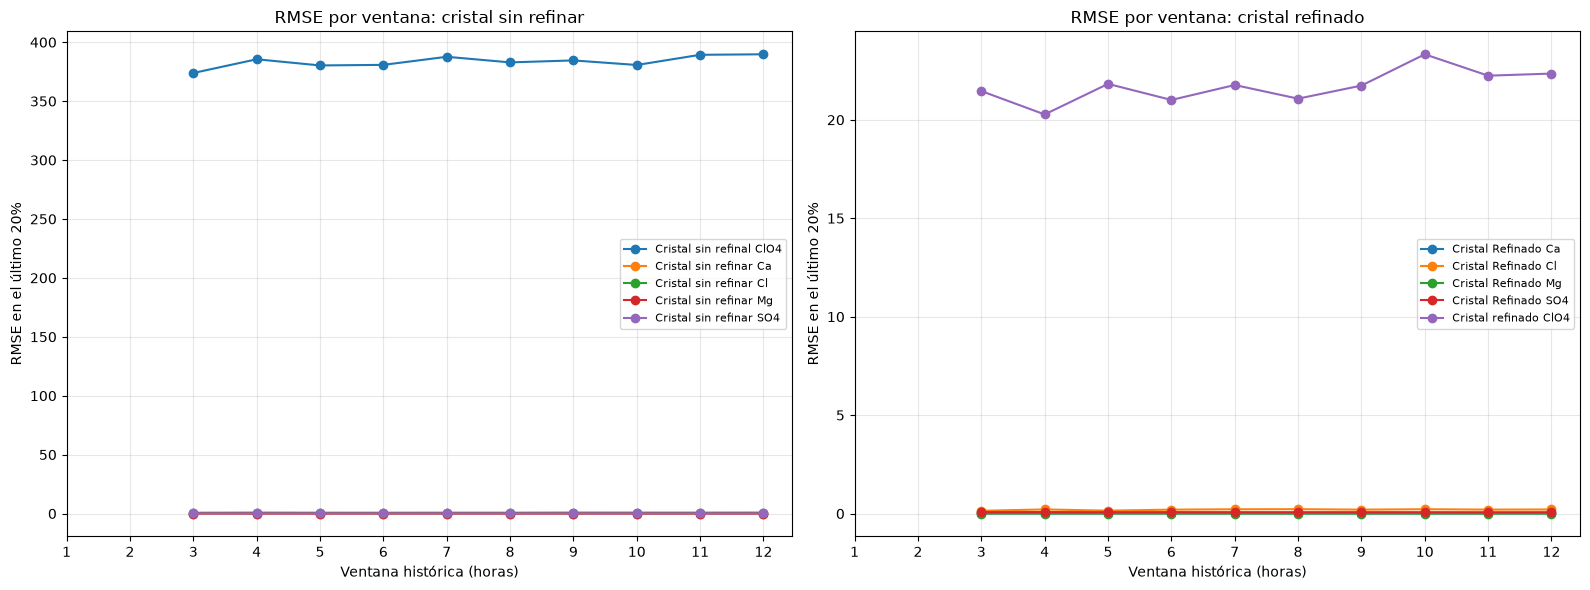

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)
for ax, product in zip(axes, ["Sin Refinar", "Refinado"]):
    subset = resultados[resultados["Producto"] == product]
    for target, group in subset.groupby("Analito"):
        ax.plot(group["Ventana_h"], group["RMSE"], marker="o", label=target)
    ax.set_title(f"RMSE por ventana: cristal {product.lower()}")
    ax.set_xlabel("Ventana histórica (horas)")
    ax.set_ylabel("RMSE en el último 20%")
    ax.set_xticks(range(1, MAX_WINDOW + 1))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [24]:
from pathlib import Path

if resultados.empty:
    raise ValueError("No hay resultados de ventanas para guardar.")

mejores_ventanas = (
    resultados
    .sort_values(["Producto", "Analito", "RMSE", "Ventana_h"])
    .groupby(["Producto", "Analito"], as_index=False)
    .first()
    [["Producto", "Analito", "Ventana_h",
      "n_entrenamiento", "n_prueba", "R2", "MAE", "RMSE", "NRMSE"]]
)

carpeta = Path("resultados_modelo")
carpeta.mkdir(parents=True, exist_ok=True)
archivo = carpeta / "mejores_ventanas.xlsx"

with pd.ExcelWriter(archivo) as writer:
    mejores_ventanas.to_excel(
        writer, sheet_name="Mejor por analito", index=False
    )
    resultados.to_excel(
        writer, sheet_name="Comparacion ventanas", index=False
    )

display(mejores_ventanas)
print(f"Resultados guardados en: {archivo.resolve()}")

,Producto,Analito,Ventana_h,n_entrenamiento,n_prueba,R2,MAE,RMSE,NRMSE
0,Refinado,Cristal Refinado Ca,12,3412,849,0.063716,0.005735,0.007467,0.967618
1,Refinado,Cristal Refinado Cl,3,3291,800,-144.081296,0.084217,0.142874,12.044970
2,Refinado,Cristal Refinado Mg,9,3415,849,0.049046,0.002039,0.002870,0.975169
3,Refinado,Cristal Refinado SO4,11,3231,848,0.026108,0.048013,0.068902,0.986859
4,Refinado,Cristal refinado ClO4,4,3235,848,-0.131391,12.709095,20.272393,1.063669
5,Sin Refinar,Cristal sin refinal ClO4,3,3077,750,0.043091,251.883609,373.889481,0.978217
6,Sin Refinar,Cristal sin refinar Ca,6,2733,801,0.172037,0.008617,0.010570,0.909925
7,Sin Refinar,Cristal sin refinar Cl,3,3080,801,-2.304459,0.361349,0.681722,1.817817
8,Sin Refinar,Cristal sin refinar Mg,8,3081,799,0.626029,0.021713,0.027751,0.611531
9,Sin Refinar,Cristal sin refinar SO4,10,3083,801,-0.100260,0.087205,0.115858,1.048933


Resultados guardados en: /mnt/c/Users/SrLeo/Desktop/SQM/Predicción efecto de analitos/resultados_modelo/mejores_ventanas.xlsx


### 7. Lectura de resultados

Compara las ventanas **por analito**, porque los cinco objetivos de cada producto pueden tener distinta frecuencia de observación y escala. La tabla `mejores_ventanas` ordena por RMSE dentro de cada analito; no fija una ventana universal ni afirma que una variable cause el resultado.

El período de prueba es el tramo final consecutivo del calendario. La cantidad de observaciones evaluadas puede ser menor que el 20% de las filas porque solo se puntúan timestamps con un valor observado para el analito objetivo.